# Testing New Cloud Filter
Uses an approach where it calculates cloud percentage of each pixel and then sums these values and discards image if above a certain threshold. Derived from Karinas cloud filter for Sentinel 2 imagery

## Setup

In [195]:
# -----Paths in directory
# Name of study site used for output file names
site_name = 'Panmah_Glacier'
# path to folder containing AOI file
aoi_path = '/Users/SILASTWICKLER/ws/HMA/snowCover/study_sites/' + site_name + '/AOIs/'
# AOI file name
aoi_fn = site_name + '_outline.shp' 
# path to folder containing dem raster file
dem_path = '/Users/SILASTWICKLER/ws/HMA/snowCover/study_sites/' + site_name + '/DEMs/'
# DEM file name
# Note: set dem_fn=None if you want to use the ArcticDEM or NASADEM via Google Earth Engine
dem_fn = None
# path to PlanetScope images
# Note: set ps_im_path=None if not using PlanetScope
ps_im_path = None #out_path + 'PlanetScope/raw_images/'

# -----Define image search settings
# Google Earth Engine project ID (default = "ee-{YOUR USER NAME}")
project_id = 'ee-silastwickler'
# date ranges (inclusive)
date_start = '2019-06-01'
date_end = '2019-06-30'
month_start = 6
month_end = 10
# whether to mask clouds in images
#mask_clouds = True
# minimum portion of AOI covered after cloud filtering
min_aoi_coverage = 70

max_cloud_cover = 20

out_path = aoi_path + '/test_cloud_filter/' + str(max_cloud_cover) +'/'

# -----Determine image download, clipping & plotting settings
# Note: if im_download = False, but images over the aoi exceed GEE limit, images must be downloaded regardless.
im_download = False  # = True to download all satellite images by default
delineate_snowline = False # = True to delineate the snowline in classified images
plot_results = True # = True to plot figures of results for each image where applicable
verbose = True # = True to print details for each image during each step
skip_clipped = False # = True to skip PlanetScope images where bands appear "clipped", i.e. max(blue) < 0.8

#######################

# -----Import packages
import xarray as xr
import os
import glob
import numpy as np
from matplotlib import pyplot as plt
import geopandas as gpd
import sys
import ee
import json
from tqdm.auto import tqdm
from joblib import load
from shapely.geometry import MultiPolygon, Polygon
import warnings
warnings.filterwarnings('ignore')

# -----Make output directory if it doesn't exist
if not os.path.exists(out_path):
    os.mkdir(out_path)
    print('Made directory for outputs: ', out_path)

# -----Set paths for output files
s2_toa_im_path = os.path.join(out_path, 'Sentinel-2_TOA_filter')
s2_sr_im_path = os.path.join(out_path, 'Sentinel-2_SR_filter')
s2_toa_im_path_no_filter = os.path.join(out_path, 'Sentinel-2_TOA_no_filter')
s2_sr_im_path_no_filter = os.path.join(out_path, 'Sentinel-2_SR_no_filter')
l_im_path = os.path.join(out_path, 'Landsat')
l_im_path_no_filter = os.path.join(out_path, 'Landsat_no_filter')
ps_im_masked_path = os.path.join(out_path, 'PlanetScope', 'masked')
ps_im_mosaics_path = os.path.join(out_path, 'PlanetScope', 'mosaics')
im_classified_path = os.path.join(out_path, 'classified')
snow_cover_stats_path = os.path.join(out_path, 'snow_cover_stats')
figures_out_path = os.path.join(out_path, 'figures')

# -----Import pipeline utilities
# When running locally, must import from "functions" folder
script_path = os.getcwd()
if "functions" in os.listdir(os.path.join(script_path, '..')):
    sys.path.append(os.path.join(script_path, '..', 'functions'))
# In Docker image, all files are in "/app" folder
else:
    sys.path.append(os.path.join(script_path))

# -----Load dataset dictionary
dataset_dict_fn = os.path.join(script_path, '..', 'inputs-outputs', 'datasets_characteristics.json')
dataset_dict = json.load(open(dataset_dict_fn))

In [190]:
try:
    ee.Initialize(project=project_id)
except: 
    ee.Authenticate()
    ee.Initialize(project=project_id)

## Functions

In [193]:
import math
import geopandas as gpd
import pandas as pd
import ee
import geedim as gd
import requests
from shapely.geometry import MultiLineString, LineString, Point
import os
import xarray as xr
import numpy as np
import rioxarray as rxr
from scipy.ndimage import binary_fill_holes, binary_dilation
from skimage.measure import find_contours
from scipy.interpolate import interp1d
import matplotlib.pyplot as plt
import matplotlib
from tqdm.auto import tqdm
from sklearn.exceptions import NotFittedError
import PIL
import io
import wxee as wx
import rasterio as rio
import datetime

def S2SRcloudpercent(image,ROI):
    aveCloud = image.select('MSK_CLDPRB').reduceRegion(
        reducer=ee.Reducer.mean(),
        geometry=ROI,
        maxPixels=1e9
        )
    return image.set({'CLOUDY_PIXEL_PERCENTAGE': aveCloud.get('MSK_CLDPRB')})

def S2TOAcloudpercent(image, aoi):
    # Using QA60 bitmask (bit 10 = clouds, bit 11 = cirrus)
    qa = image.select('QA60')
    cloud_bit = 1 << 10
    cirrus_bit = 1 << 11
    cloud_mask = qa.bitwiseAnd(cloud_bit).eq(0).And(qa.bitwiseAnd(cirrus_bit).eq(0))

    # cloud_mask == 1 means clear; invert to get "is cloud"
    is_cloud = cloud_mask.eq(0)

    cloud_stats = is_cloud.reduceRegion(
        reducer=ee.Reducer.mean(),
        geometry=aoi,
        scale=60,           # match QA60 native resolution
        maxPixels=1e9
    )

    cloud_pct = ee.Number(cloud_stats.get('QA60')).multiply(100)

    return image.set('ROI_CLOUD_COVER', cloud_pct)

def LScloudpercent(image, ROI):
    # Using QA_PIXEL bitmask (Landsat Collection 2 Level-2)
    # bit 1 = Dilated Cloud, bit 2 = Cirrus, bit 3 = Cloud, bit 4 = Cloud Shadow
    qa = image.select('QA_PIXEL')
    dilated_cloud_bit = 1 << 1
    cirrus_bit = 1 << 2
    cloud_bit = 1 << 3
    shadow_bit = 1 << 4

    clear_mask = (qa.bitwiseAnd(dilated_cloud_bit).eq(0)
                  .And(qa.bitwiseAnd(cirrus_bit).eq(0))
                  .And(qa.bitwiseAnd(cloud_bit).eq(0))
                  .And(qa.bitwiseAnd(shadow_bit).eq(0)))

    # clear_mask == 1 means clear; invert to get "is cloud/shadow"
    is_cloud = clear_mask.eq(0)

    cloud_stats = is_cloud.reduceRegion(
        reducer=ee.Reducer.mean(),
        geometry=ROI,
        scale=30,            # match QA_PIXEL native resolution
        maxPixels=1e9
    )

    cloud_pct = ee.Number(cloud_stats.get('QA_PIXEL')).multiply(100)
    print(cloud_pct)
    return image.set('ROI_CLOUD_COVER', cloud_pct)


def split_date_range(aoi_area, dataset, start_date, end_date, start_month, end_month, verbose):
    """
    Split a date range into smaller chunks to mitigate computation time-out based on the area of the AOI:
        - AOI < 500 km2: split by month
        - 700 km2 <= AOI < 1100 km2: split by week
        - AOI >= 1100 km2: split by day

    Enforces dataset availability windows:
        - Sentinel-2_TOA: available from 2016
        - Sentinel-2_SR: available from 2019
        - Landsat 8/9: available from 2013

    For the largest glaciers, user memory limits will still be exceeded, even when querying at daily resolution. 
    Therefore, this function will also return the image spatial resolution (scale) required to prevent computation time out.
    For glaciers within the area limits, it will return the default scale for Sentinel-2 (10 m) and Landsat 8/9 (30 m). 
    """
    
    # Convert string inputs to datetime objects
    start_date = datetime.datetime.strptime(start_date, "%Y-%m-%d").date()
    end_date = datetime.datetime.strptime(end_date, "%Y-%m-%d").date()

    # Enforce dataset availability
    dataset_start_years = {
        "Sentinel-2_TOA": 2016,
        "Sentinel-2_SR": 2019,
        "Landsat": 2013,
    }

    if dataset not in dataset_start_years:
        raise ValueError(f"Unsupported dataset: {dataset}")

    min_year = dataset_start_years[dataset]
    start_date = max(start_date, datetime.date(min_year, 1, 1))  # Clamp to dataset availability

    # List to hold date range tuples
    ranges = []


    print('Splitting date range by month for image query.')
    for year in range(start_date.year, end_date.year + 1):
        for month in range(start_month, end_month+1):
            if (year == start_date.year and month < start_month) or (year == end_date.year and month > end_month):
                continue
            start = datetime.date(year, month, 1)
            end = datetime.date(year + 1, 1, 1) - datetime.timedelta(days=1) if month == 12 else datetime.date(year, month + 1, 1) - datetime.timedelta(days=1)
            start = max(start, start_date)
            end = min(end, end_date)
            if start <= end:
                ranges.append((start.isoformat(), end.isoformat()))

    if verbose:
        print(f"Number of date ranges = {len(ranges)}")

    return ranges


def query_gee_for_imagery(aoi_utm, dataset, start_date, end_date, start_month, end_month, cloud_mask, max_cloud_cover,
                          percent_aoi_coverage, im_download, out_path, dataset_dict, site_name,
                          im_classified_path, scs_path, clf, feature_cols, figures_out_path,
                          plot_results, verbose, delineate_snowline=False):
    """

    Parameters
    ----------
    aoi_utm: geopandas.geodataframe.GeoDataFrame
        Area of interest for querying and clipping imagery.
    dataset: str
        Name of dataset: "Landsat", "Sentinel-2_SR", or "Sentinel-2_TOA"
    start_date: str
        Start date for image querying, format: "YYYY-MM-DD"
    end_date: str
        End date for image querying, format: "YYYY-MM-DD"
    start_month: int
        Start month for image querying, inclusive
    end_month: int
        End month for image querying, inclusive
    percent_aoi_coverage: int/float
        Minimum percent coverage of the AOI after cloud masking for filtering images (e.g., 50% AOI coverage = 50).
    im_download: bool
        Whether to download images to out_path. If image sizes exceed the GEE user memory limit (10 MB), images will be
        downloaded regardless.
    out_path: str
        Path for output images. Only used if im_download = True or image sizes exceed the GEE user memory limit
    run_pipeline: bool
        Whether to run the classification pipeline for each image.
    -----Options if run_pipeline=True-----
    dataset_dict: dict
        Dictionary of dataset characteristics
    site_name: str
        Name of site, used for output file names
    im_classified_path: str
        Path in directory where classified images will be saved
    scs_path: str
        Path in directory where snow cover statistics will be saved
    clf: sklearn pre-trained model
        classifier applied to the input image, specific to image dataset
    feature_cols: list of str
        features (i.e., image bands and NDSI) to use for classifying
    figures_out_path: str
        path where figures will be saved
    plot_results: bool
        whether to plot results and save figure
    verbose: bool
        whether to output details about each image
    delineate_snowline: bool
        whether to delineate snowline in each classified image

    Returns
    -------

    """
    # Load and reformat AOI as ee.Geometry.Polygon
    epsg_utm = aoi_utm.crs.to_epsg()
    aoi_wgs = aoi_utm.to_crs("EPSG:4326")
    aoi_ee = ee.Geometry.Polygon(list(zip(aoi_wgs.geometry[0].exterior.coords.xy[0],
                                          aoi_wgs.geometry[0].exterior.coords.xy[1])))
    # Calculate the total area of the AOI
    aoi_area = aoi_ee.area().getInfo()

    # Define dataset-specific properties
    scale = dataset_dict[dataset]['resolution_m']
    analysis_bands = [x for x in feature_cols if x != 'NDSI']
    ndsi_bands = dataset_dict[dataset]['NDSI_bands']

    # Split date range into smaller date ranges as necessary
    date_ranges = split_date_range(aoi_area, dataset, start_date, end_date, start_month, end_month, verbose=verbose)
    print(f'Number of date ranges to loop through = '+str(len(date_ranges)))

    # Run the workflow for each day in date range separately
    #CST 09012026 im_xr_list needs to be initialized outside of the initial for loop
    im_xr_list = []
    for date_range in tqdm(date_ranges):
        print(f'date range for image query = '+str(date_range))
        # Query for imagery
        if dataset == 'Landsat':
            # Get full collection for dates and bounds
            if cloud_mask:
                im_col = (ee.ImageCollection("LANDSAT/LC08/C02/T1_L2").merge(ee.ImageCollection("LANDSAT/LC09/C02/T1_L2"))
                      .filterBounds(aoi_ee)
                      .filter(ee.Filter.date(date_range[0], date_range[1]))
                      .filter(ee.Filter.calendarRange(start_month, end_month, 'month'))
                      .map(lambda image: LScloudpercent(image, aoi_ee))
                      .filterMetadata('ROI_CLOUD_COVER', 'less_than', max_cloud_cover)
                      .select(analysis_bands)
                      )
            else: 
                im_col = (ee.ImageCollection("LANDSAT/LC08/C02/T1_L2").merge(ee.ImageCollection("LANDSAT/LC09/C02/T1_L2"))
                      .filterBounds(aoi_ee)
                      .filter(ee.Filter.date(date_range[0], date_range[1]))
                      .filter(ee.Filter.calendarRange(start_month, end_month, 'month'))
                      .select(analysis_bands)
                      )
            # Apply scale factors
            def apply_scale_factors(image):
                adjusted_bands = image.multiply(0.0000275).add(-0.2)
                return image.addBands(adjusted_bands, None, True).copyProperties(ee.Image(image))
            im_col = im_col.map(apply_scale_factors)
        elif (dataset == 'Sentinel-2_SR') or (dataset == 'Sentinel-2_TOA'):
            # Get full collection for dates and bounds
            if dataset == 'Sentinel-2_TOA':
                col_name = "COPERNICUS/S2_HARMONIZED"
                if cloud_mask:
                    im_col = (ee.ImageCollection(col_name)
                          .filterBounds(aoi_ee)
                          .filter(ee.Filter.date(date_range[0], date_range[1]))
                          .filter(ee.Filter.calendarRange(start_month, end_month, 'month'))
                          .map(lambda image: S2TOAcloudpercent(image, aoi_ee))
                          .filterMetadata('ROI_CLOUD_COVER', 'less_than', max_cloud_cover)
                          .select(analysis_bands)
                          )
            elif dataset == 'Sentinel-2_SR':
                col_name = "COPERNICUS/S2_SR_HARMONIZED"
                if cloud_mask:
                    im_col = (ee.ImageCollection(col_name)
                          .filterBounds(aoi_ee)
                          .filter(ee.Filter.date(date_range[0], date_range[1]))
                          .filter(ee.Filter.calendarRange(start_month, end_month, 'month'))
                          .map(lambda image: S2SRcloudpercent(image, aoi_ee))
                          .filterMetadata('CLOUDY_PIXEL_PERCENTAGE', "less_than", max_cloud_cover)
                          .select(analysis_bands)
                          )
            if cloud_mask == False:
                im_col = (ee.ImageCollection(col_name)
                      .filterBounds(aoi_ee)
                      .filter(ee.Filter.date(date_range[0], date_range[1]))
                      .filter(ee.Filter.calendarRange(start_month, end_month, 'month'))
                      .select(analysis_bands)
                      )
            # Apply scale factors
            def apply_scale_factors(image):
                adjusted_bands = image.multiply(0.0001)
                return image.addBands(adjusted_bands, None, True).copyProperties(ee.Image(image))
            im_col = im_col.map(apply_scale_factors)
        else:
            print(
                "'dataset' variable not recognized. Please set to 'Landsat', 'Sentinel-2_TOA', or 'Sentinel-2_SR'. "
                "Exiting...")
            return
    
        # Clip to AOI
        def clip_to_aoi(image):
            return image.clip(aoi_ee).copyProperties(ee.Image(image))

        im_col = im_col.map(clip_to_aoi)

        # Sort by capture date
        im_col = im_col.sort('system:time_start')

        # Add NDSI band
        def calculate_ndsi(image):
            ndsi = image.expression(
                '((GREEN - SWIR1) / (GREEN + SWIR1))',
                {'GREEN': image.select(ndsi_bands[0]),
                 'SWIR1': image.select(ndsi_bands[1])}).rename('NDSI')
            return image.addBands(ndsi, None, True)
        im_col = im_col.map(calculate_ndsi)

        # Mosaic images captured same day
        def mosaic_image_collection_by_date(collection):
            # Functions to mosaic images for each date
            def mosaic_by_date(date_str):
                date = ee.Date(date_str)
                # Filter images by the date
                day_images = collection.filter(ee.Filter.date(date, date.advance(1, 'day')))
                # Mosaic the images for this date
                return day_images.mosaic().set({'system:time_start': date.millis(), 'date': date_str})
            # Map over each unique date and create mosaics
            mosaics_collection = dates.map(lambda d: mosaic_by_date(d))
            return ee.ImageCollection(mosaics_collection)
        # Create a list of unique dates in the collection
        dates = im_col.aggregate_array('system:time_start').map(lambda t: ee.Date(t).format('YYYY-MM-dd')).distinct()
        im_col_mosaicked = mosaic_image_collection_by_date(im_col)

        # Calculate % coverage of the AOI
        def calculate_percent_image_aoi_coverage(ee_image):
            # Create binary image of masked (0) and unmasked (1) pixels
            unmasked_pixels = ee_image.mask().reduce(ee.Reducer.allNonZero()).selfMask()
            # Calculate the area of unmasked pixels in the ROI
            pixel_area = ee.Image.pixelArea()
            aoi_area = aoi_ee.area()
            unmasked_area = unmasked_pixels.multiply(pixel_area).reduceRegion(
                reducer=ee.Reducer.sum(),
                geometry=aoi_ee,
                scale=scale,
                maxPixels=1e13
            ).get('all')
            # Calculate the percentage of the ROI covered by unmasked pixels
            percentage_unmasked = ee.Number(unmasked_area).divide(aoi_area).multiply(100)
            return ee_image.set('percent_AOI_coverage', percentage_unmasked).copyProperties(ee_image)
        im_col_mosaicked = im_col_mosaicked.map(calculate_percent_image_aoi_coverage)

        # Filter based on percent coverage of the ROI
        im_col_mosaicked_filtered = im_col_mosaicked.filter(ee.Filter.gte('percent_AOI_coverage', percent_aoi_coverage))

        # Determine whether images must be downloaded to file
        if not im_download:
            # Estimate image size
            #image_size_bits = aoi_area.getInfo() / (scale ** 2) * len(analysis_bands) * 64
            #CST 09012026 fixed aoi_area.getInfo() to aoi_area
            image_size_bits = aoi_area / (scale ** 2) * len(analysis_bands) * 64
            image_size_mb = image_size_bits / (8 * 1024 * 1024)
            # If image size > 10 MB, images must be downloaded
            if image_size_mb > 10:
                im_download = True
                print('Image sizes exceed GEE user limit, images must be downloaded to file.')
            # else:
            #     print('Images are within GEE user limit, no need to download.')
        # Make sure out_path exists if downloading files
        if im_download:
            if not os.path.exists(out_path):
                os.mkdir(out_path)

        # Download images by date
        #CST 09012026 im_xr_list needs to be initialized outside of the initial for loop
        #im_xr_list = []
        dates = im_col_mosaicked_filtered.aggregate_array('system:time_start').map(
            lambda t: ee.Date(t).format('YYYY-MM-dd')).distinct().getInfo()
        print(f'number of dates in subsetted image collection '+str(len(dates)))
        for date in tqdm(dates):
            im = im_col_mosaicked_filtered.filter(ee.Filter.date(date, str(np.datetime64(date)
                                                                           + np.timedelta64(1, 'D')))).first()
            if im_download:
                im_gd = gd.MaskedImage(im, mask=False)
                # Determine file name
                im_fn = os.path.join(out_path, f"{str(date).replace('-','')}_{dataset}.tif")
                # Download to file
                download_bands = analysis_bands + ['NDSI']
                if not os.path.exists(im_fn):
                    im_gd.download(im_fn, region=aoi_ee, scale=scale, bands=download_bands, crs='EPSG:4326')
                # Open from file
                im_da = rxr.open_rasterio(im_fn)
                im_xr = im_da.to_dataset('band')
                # rename bands
                im_xr = im_xr.rename({i + 1: name for i, name in enumerate(download_bands)})
                # set CRS
                im_xr.rio.write_crs('EPSG:4326', inplace=True)
                # Add time dimension
                im_xr = im_xr.expand_dims(dim={'time': [np.datetime64(date, 'ns')]})
                if 'date' not in im_xr.attrs:
                    im_xr.attrs['date'] = date
            else:
                im_xr = im.wx.to_xarray(region=aoi_ee, scale=scale, crs='EPSG:4326')

            # Reproject to UTM for better distance calculations later
            im_xr = im_xr.rio.write_crs("EPSG:4326")
            im_xr = im_xr.rio.reproject(f'EPSG:{epsg_utm}', nodata=np.nan)
            
            im_xr_list += [im_xr]

    return im_xr_list


def plot_xr_rgb_image(im_xr, rgb_bands):
    """Plot RGB image of xarray.DataSet

    Parameters
    ----------
    im_xr: xarray.DataSet
        Dataset containing image bands in data variables with x, y, and time coordinates.
        Function assumed x and y coordinates are in units of meters.
    rgb_bands: List
        List of data variable names for RGB bands contained within the dataset, e.g. ['red', 'green', 'blue']

    Returns
    ----------
    fig: matplotlib.pyplot.figure
        figure handle for the resulting plot
    ax: matplotlib.pyplot.figure.Axes
        axis handle for the resulting plot
    """

    # -----Grab RGB bands from dataset
    if len(np.shape(im_xr[rgb_bands[0]].data)) > 2:  # check if a dimension must be cut from the band data
        red = im_xr[rgb_bands[0]].data[0]
        blue = im_xr[rgb_bands[1]].data[0]
        green = im_xr[rgb_bands[2]].data[0]
    else:
        red = im_xr[rgb_bands[0]].data
        blue = im_xr[rgb_bands[1]].data
        green = im_xr[rgb_bands[2]].data

    # -----Format datatype as float, rescale RGB pixel values from 0 to 1
    red, green, blue = red.astype(float), green.astype(float), blue.astype(float)
    im_min = np.nanmin(np.ravel([red, green, blue]))
    im_max = np.nanmax(np.ravel([red, green, blue]))
    red = ((red - im_min) * (1 / (im_max - im_min)))
    green = ((green - im_min) * (1 / (im_max - im_min)))
    blue = ((blue - im_min) * (1 / (im_max - im_min)))

    # -----Plot
    fig, ax = plt.subplots(1, 1, figsize=(8, 6))
    ax.imshow(np.dstack([red, green, blue]),
              extent=(np.min(im_xr.x.data) / 1e3, np.max(im_xr.x.data) / 1e3, np.min(im_xr.y.data) / 1e3,
                      np.max(im_xr.y.data) / 1e3))
    ax.grid()
    ax.set_xlabel('Easting [km]')
    ax.set_ylabel('Northing [km]')

    return fig, ax

def plot_cloud_cover_comp(no_cloud_filt, cloud_filt, rgb_bands, im_date, dataset, figures_out_path):
    """
    no_cloud_filt: im_xr for non cloud filtered image
    cloud_filt: im_xr for cloud filtered image
    im_date: Image date 
    dataset: Satellite from which image was derived from 
    figures_out_path: file path for figure to be saved to
    """
    if (not os.path.exists(figures_out_path)) & plot_results:
        os.mkdir(figures_out_path)
        print('Made directory for output figures: ' + figures_out_path)
        
    fig, ax = plt.subplots(1, 2, figsize=(14, 6))
    # define x and y limits
    xmin, xmax = aoi.geometry[0].buffer(0.01).bounds[0] / 1e3, aoi.geometry[0].buffer(0.01).bounds[2] / 1e3
    ymin, ymax = aoi.geometry[0].buffer(0.01).bounds[1] / 1e3, aoi.geometry[0].buffer(0.01).bounds[3] / 1e3
    
    # RGB image
    #no_cloud_filt = no_cloud_filt[0]
    no_cloud_filt = no_cloud_filt.isel(time=0)
    ax[0].imshow(np.dstack([no_cloud_filt[dataset_dict[dataset]['RGB_bands'][0]].values,
                                    no_cloud_filt[dataset_dict[dataset]['RGB_bands'][1]].values,
                                    no_cloud_filt[dataset_dict[dataset]['RGB_bands'][2]].values]),
                         extent=(np.min(no_cloud_filt.x.data) / 1e3, np.max(no_cloud_filt.x.data) / 1e3,
                                 np.min(no_cloud_filt.y.data) / 1e3, np.max(no_cloud_filt.y.data) / 1e3))

    ax[0].set_ylabel('Northing [km]')
    ax[0].set_xlabel('Easting [km]')
    
    # cloud filtered image
    #cloud_filt = cloud_filt[0]
    if len(cloud_filt) != 0:
        cloud_filt = cloud_filt[0]
        cloud_filt = cloud_filt.isel(time=0)
        ax[1].imshow(np.dstack([cloud_filt[dataset_dict[dataset]['RGB_bands'][0]].values,
                                        cloud_filt[dataset_dict[dataset]['RGB_bands'][1]].values,
                                        cloud_filt[dataset_dict[dataset]['RGB_bands'][2]].values]),
                             extent=(np.min(cloud_filt.x.data) / 1e3, np.max(cloud_filt.x.data) / 1e3,
                                     np.min(cloud_filt.y.data) / 1e3, np.max(cloud_filt.y.data) / 1e3))
        
       
        ax[1].set_xlabel('Easting [km]')

    #display(fig)
        
    # AOI
    '''
    boundary = aoi.geometry[0].boundary
    if isinstance(boundary, MultiLineString):
        for ii, geom in enumerate(aoi.geometry[0].boundary.geoms):
            if ii > 0:
                label = '_nolegend_'
            else:
                label = 'AOI'
            ax[0].plot(np.divide(geom.coords.xy[0], 1e3),
                       np.divide(geom.coords.xy[1], 1e3), '-k', linewidth=1, label=label)
            ax[1].plot(np.divide(geom.coords.xy[0], 1e3),
                       np.divide(geom.coords.xy[1], 1e3), '-k', linewidth=1, label=label)
    elif isinstance(boundary, (LineString, LinearRing)):
        ax[0].plot(np.divide(aoi.geometry[0].boundary.coords.xy[0], 1e3),
                   np.divide(aoi.geometry[0].boundary.coords.xy[1], 1e3), '-k', linewidth=1, label='AOI')
        ax[1].plot(np.divide(aoi.geometry[0].boundary.coords.xy[0], 1e3),
                   np.divide(aoi.geometry[0].boundary.coords.xy[1], 1e3), '-k', linewidth=1, label='AOI')

    # reset x and y limits
    ax[0].set_xlim(xmin, xmax)
    ax[0].set_ylim(ymin, ymax)
    ax[1].set_xlim(xmin, xmax)
    ax[1].set_ylim(ymin, ymax)
    # add legend
    handles, labels = ax[1].get_legend_handles_labels()
    fig.legend(handles, labels, loc='lower center', ncols=len(labels))
    '''
    # determine figure title and file name
    title = im_date + dataset + ' cloud cover comparison'
    fig.suptitle(title)
    fig.tight_layout()
    # save figure
    fig_fn = os.path.join(figures_out_path, title.replace(' ', '_').replace('-','') + '.png')
    fig.savefig(fig_fn, dpi=300, facecolor='white', edgecolor='none')
    if verbose:
        print('Figure saved to file:' + fig_fn)




## Load AOI

In [191]:
# -----Load AOI as gpd.GeoDataFrame
aoi = gpd.read_file(os.path.join(aoi_path, aoi_fn))
# reproject the AOI to WGS84 to solve for the optimal utm zone
aoi_wgs = aoi.to_crs('EPSG:4326')
aoi_wgs_centroid = [aoi_wgs.geometry[0].centroid.xy[0][0],
                    aoi_wgs.geometry[0].centroid.xy[1][0]]
# grab the optimal UTM zone EPSG code
epsg_utm = utils.convert_wgs_to_utm(aoi_wgs_centroid[0], aoi_wgs_centroid[1])
print('Optimal UTM CRS = EPSG:' + str(epsg_utm))
# reproject AOI to the optimal UTM zone
aoi_utm = aoi.to_crs(f'EPSG:{epsg_utm}')

Optimal UTM CRS = EPSG:32643


## Sentinel 2

In [117]:
# -----Query GEE for imagery and run classification pipeline
# Define dataset
dataset = 'Sentinel-2_TOA'
# Load trained image classifier
clf_fn = os.path.join(script_path, '..', 'inputs-outputs', 'Sentinel-2_TOA_classifier_all_sites.joblib')
clf = load(clf_fn)
# Load feature columns (bands to use in classification)
feature_cols_fn = os.path.join(script_path, '..', 'inputs-outputs', 'Sentinel-2_TOA_feature_columns.json')
feature_cols = json.load(open(feature_cols_fn))
# Run the classification pipeline
cloud_mask = False
non_cloud_filtered_imgs = query_gee_for_imagery(aoi_utm, dataset, date_start, date_end, month_start, month_end, cloud_mask, max_cloud_cover, min_aoi_coverage,
                                im_download, s2_toa_im_path_no_filter, dataset_dict, site_name, im_classified_path,
                                snow_cover_stats_path, clf, feature_cols, figures_out_path, plot_results, verbose, delineate_snowline)



Splitting date range by month for image query.
Number of date ranges = 1
Number of date ranges to loop through = 1


  0%|          | 0/1 [00:00<?, ?it/s]

date range for image query = ('2019-06-01', '2019-06-30')
Image sizes exceed GEE user limit, images must be downloaded to file.
number of dates in subsetted image collection 6


  0%|          | 0/6 [00:00<?, ?it/s]

Consider adjusting `region`, `scale` and/or `dtype` to reduce the 20190602_Sentinel-2_TOA.tif download size (raw: 1.16 GB).


...

20190617_Sentinel-2_TOA.tif: | | 0.00/1.16G (raw) [  0.0%] in 00:00 (eta:     ?)

Consider adjusting `region`, `scale` and/or `dtype` to reduce the 20190622_Sentinel-2_TOA.tif download size (raw: 1.16 GB).


20190622_Sentinel-2_TOA.tif: | | 0.00/1.16G (raw) [  0.0%] in 00:00 (eta:     ?)

Consider adjusting `region`, `scale` and/or `dtype` to reduce the 20190627_Sentinel-2_TOA.tif download size (raw: 1.16 GB).


20190627_Sentinel-2_TOA.tif: | | 0.00/1.16G (raw) [  0.0%] in 00:00 (eta:     ?)

Splitting date range by month for image query.
Number of date ranges = 1
Number of date ranges to loop through = 1


  0%|          | 0/1 [00:00<?, ?it/s]

date range for image query = ('2019-06-01', '2019-06-03')
Image sizes exceed GEE user limit, images must be downloaded to file.
number of dates in subsetted image collection 0


0it [00:00, ?it/s]

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.1431..1.4741].


...

  0%|          | 0/1 [00:00<?, ?it/s]

date range for image query = ('2019-06-26', '2019-06-28')
Image sizes exceed GEE user limit, images must be downloaded to file.
number of dates in subsetted image collection 0


0it [00:00, ?it/s]

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0563..1.5295].


Figure saved to file:/Users/SILASTWICKLER/ws/HMA/snowCover/study_sites/Panmah_Glacier/AOIs//test_cloud_filter/20/figures/20190627Sentinel2_TOA_cloud_cover_comparison.png
6


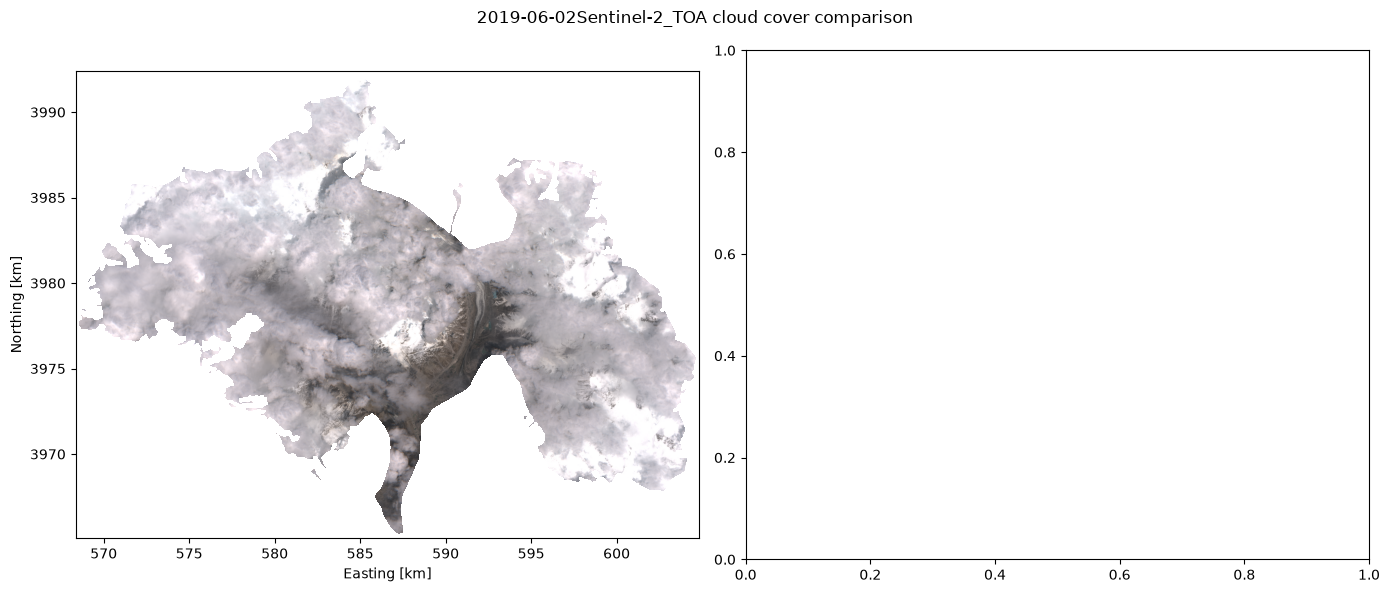

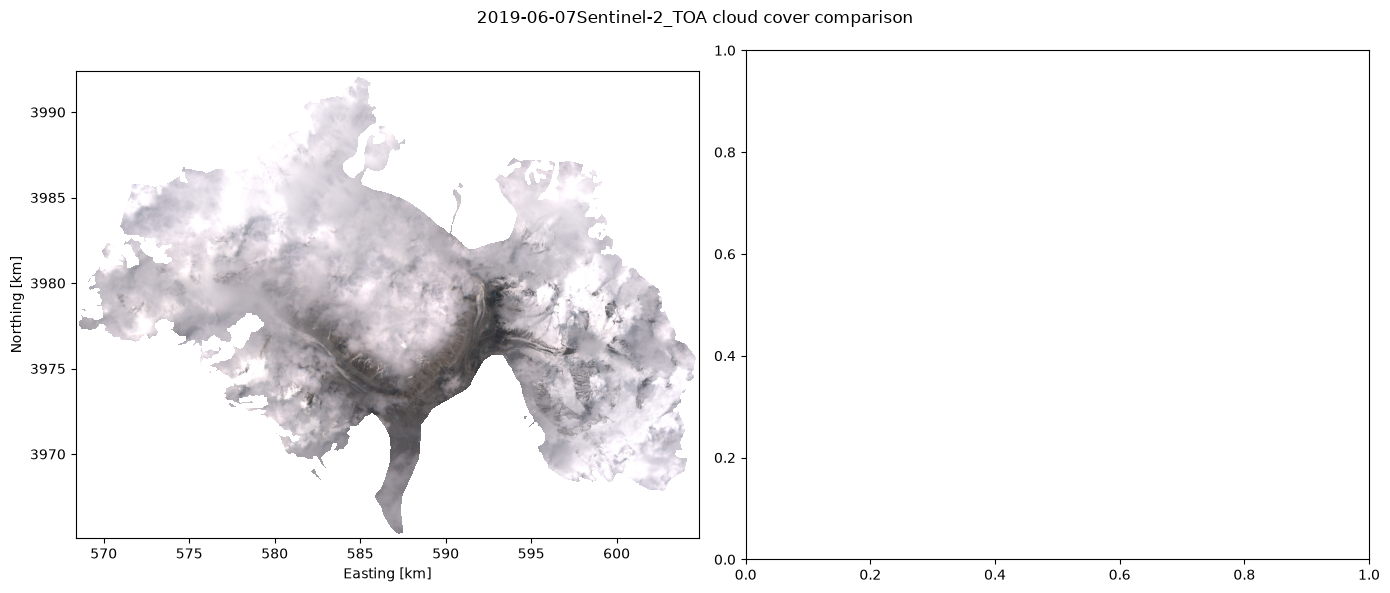

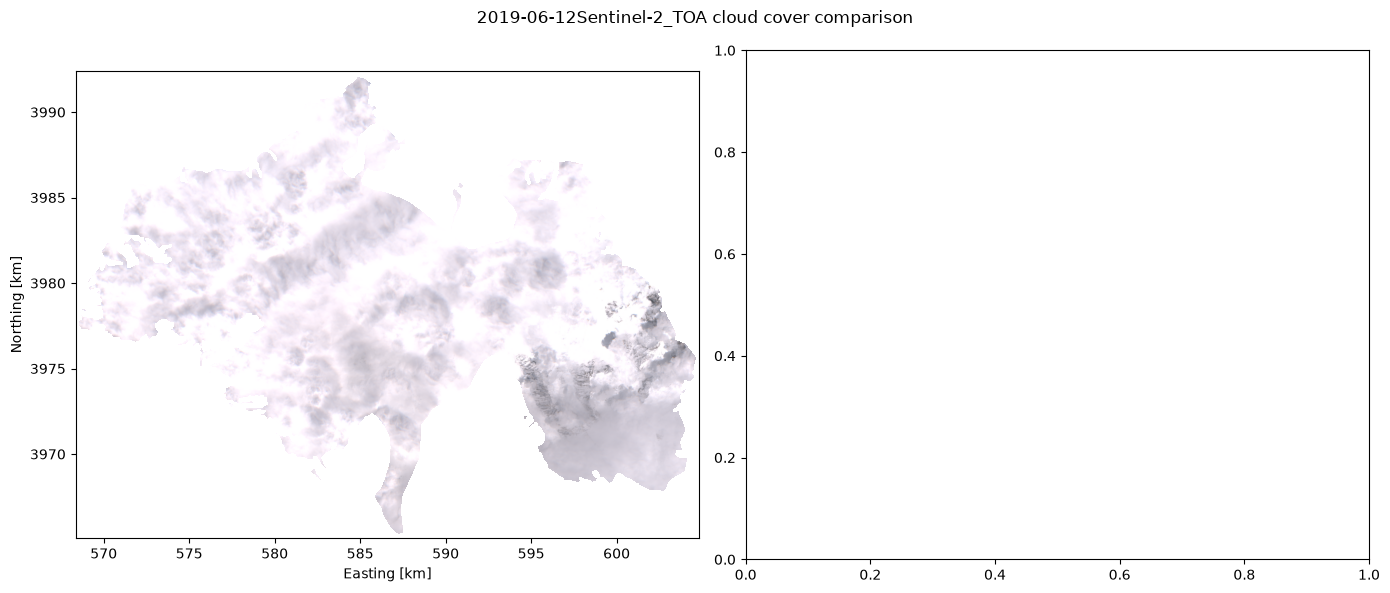

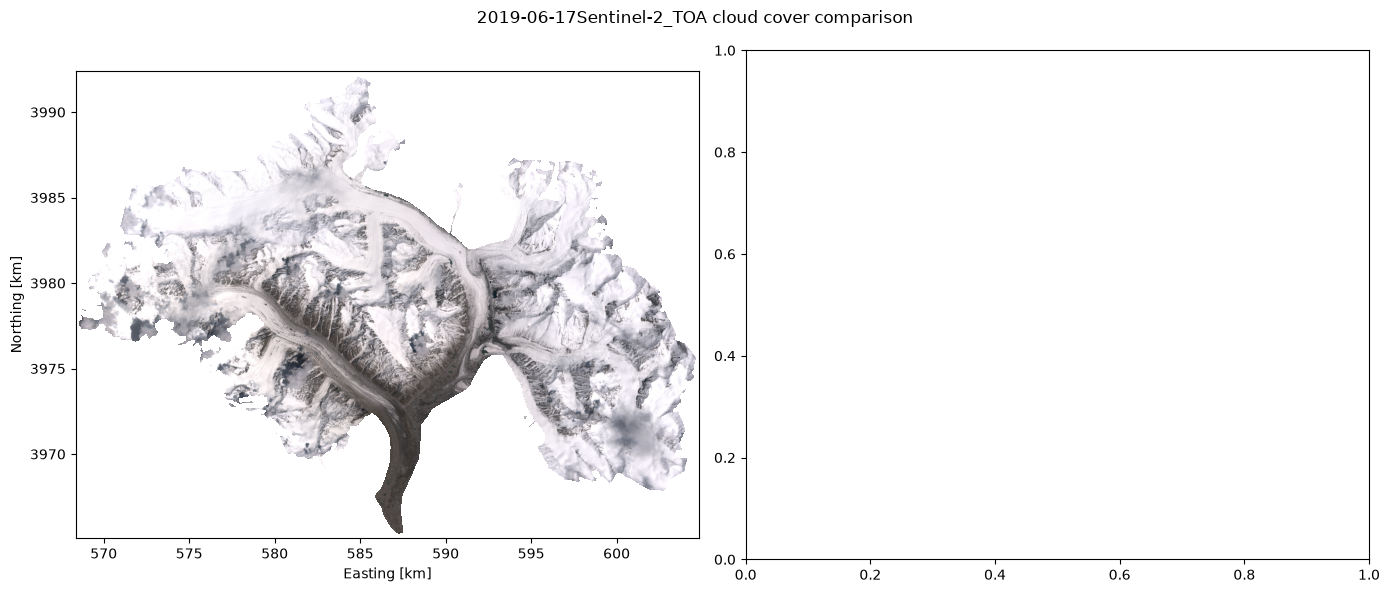

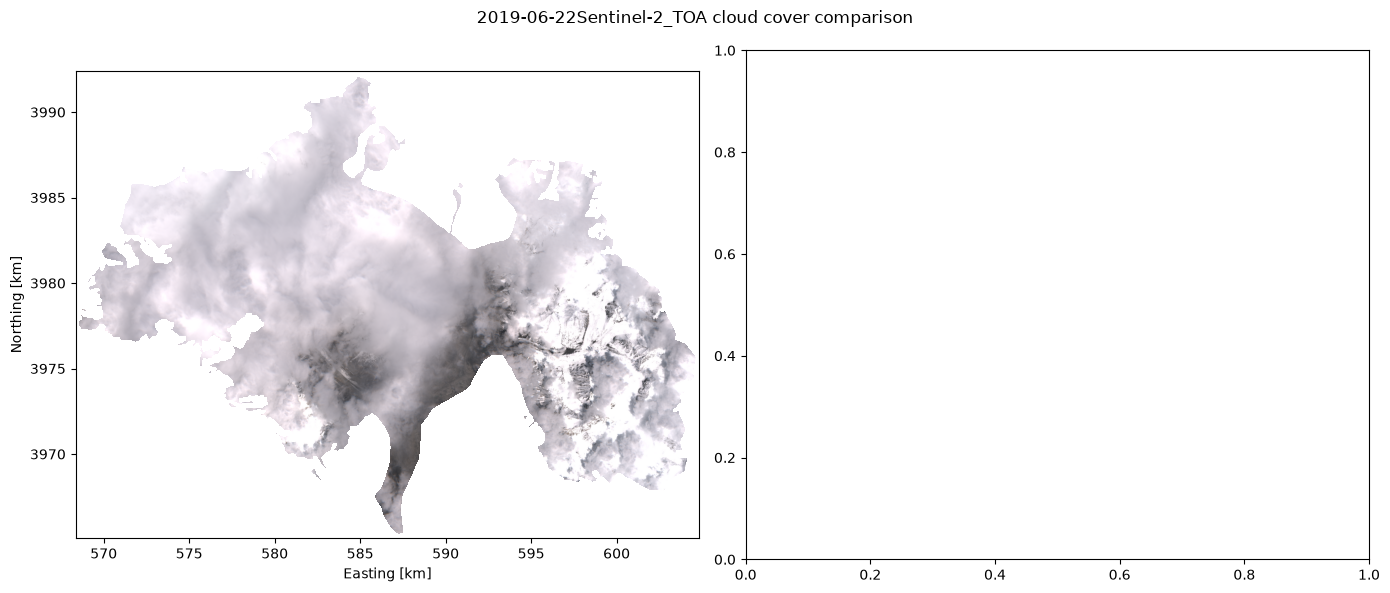

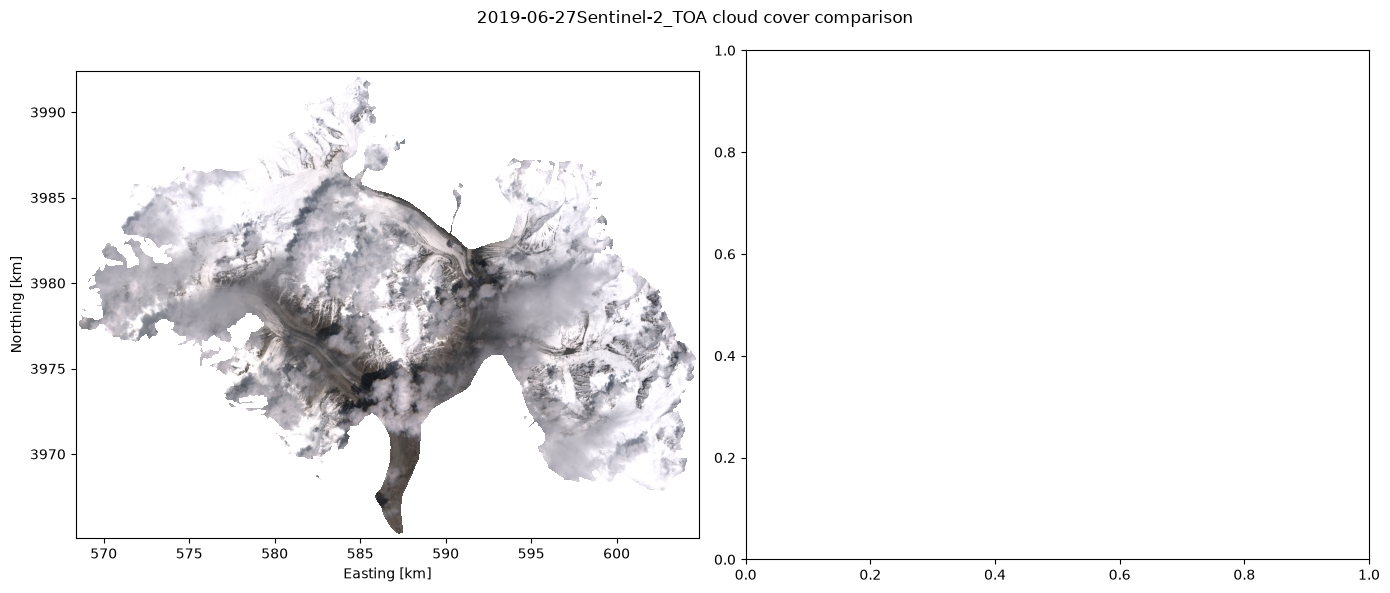

In [196]:
# Define dataset
dataset = 'Sentinel-2_TOA'
cloud_filtered_imgs = []
cloud_mask = True
for img in non_cloud_filtered_imgs:
    date = img.attrs['date']
    new_date_start = (pd.to_datetime(date) - pd.Timedelta(days=1)).strftime('%Y-%m-%d')
    new_date_end = (pd.to_datetime(date) + pd.Timedelta(days=1)).strftime('%Y-%m-%d')
    result = query_gee_for_imagery(aoi_utm, dataset, new_date_start, new_date_end, month_start, month_end, cloud_mask, max_cloud_cover, min_aoi_coverage,
                                im_download, s2_toa_im_path, dataset_dict, site_name, im_classified_path,
                                snow_cover_stats_path, clf, feature_cols, figures_out_path, plot_results, verbose, delineate_snowline)
    plot_cloud_cover_comp(img, result, dataset_dict, date, dataset, figures_out_path)
    cloud_filtered_imgs.append(result)
if len(non_cloud_filtered_imgs[0]) != 0:
    print(len(non_cloud_filtered_imgs))
else:
    print('No images collected')


In [171]:
# -----Query GEE for imagery and run classification pipeline
# Define dataset
dataset = 'Sentinel-2_SR'
# Load trained image classifier
clf_fn = os.path.join(script_path, '..', 'inputs-outputs', 'Sentinel-2_SR_classifier_all_sites.joblib')
clf = load(clf_fn)
# Load feature columns (bands to use in classification)
feature_cols_fn = os.path.join(script_path, '..', 'inputs-outputs', 'Sentinel-2_SR_feature_columns.json')
feature_cols = json.load(open(feature_cols_fn))
# Run the classification pipeline
cloud_mask = False
SR_non_filt_imgs = query_gee_for_imagery(aoi_utm, dataset, date_start, date_end, month_start, month_end, cloud_mask, max_cloud_cover, min_aoi_coverage,
                                im_download, s2_sr_im_path_no_filter, dataset_dict, site_name, im_classified_path,
                                snow_cover_stats_path, clf, feature_cols, figures_out_path, plot_results, verbose, delineate_snowline)

Splitting date range by month for image query.
Number of date ranges = 1
Number of date ranges to loop through = 1


  0%|          | 0/1 [00:00<?, ?it/s]

date range for image query = ('2019-06-01', '2019-06-30')
Image sizes exceed GEE user limit, images must be downloaded to file.
number of dates in subsetted image collection 6


  0%|          | 0/6 [00:00<?, ?it/s]

Consider adjusting `region`, `scale` and/or `dtype` to reduce the 20190602_Sentinel-2_SR.tif download size (raw: 1.16 GB).


...

20190617_Sentinel-2_SR.tif: |  | 0.00/1.16G (raw) [  0.0%] in 00:00 (eta:     ?)

Consider adjusting `region`, `scale` and/or `dtype` to reduce the 20190622_Sentinel-2_SR.tif download size (raw: 1.16 GB).


20190622_Sentinel-2_SR.tif: |  | 0.00/1.16G (raw) [  0.0%] in 00:00 (eta:     ?)

Consider adjusting `region`, `scale` and/or `dtype` to reduce the 20190627_Sentinel-2_SR.tif download size (raw: 1.16 GB).


20190627_Sentinel-2_SR.tif: |  | 0.00/1.16G (raw) [  0.0%] in 00:00 (eta:     ?)

Splitting date range by month for image query.
Number of date ranges = 1
Number of date ranges to loop through = 1


  0%|          | 0/1 [00:00<?, ?it/s]

date range for image query = ('2019-06-01', '2019-06-03')
Image sizes exceed GEE user limit, images must be downloaded to file.
number of dates in subsetted image collection 0


0it [00:00, ?it/s]

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0666..1.5648].


Figure saved to file:/Users/SILASTWICKLER/ws/HMA/snowCover/study_sites/Panmah_Glacier/AOIs//test_cloud_filter/20/figures/20190602Sentinel2_SR_cloud_cover_comparison.png
Splitting date range by month for image query.
Number of date ranges = 1
Number of date ranges to loop through = 1


  0%|          | 0/1 [00:00<?, ?it/s]

date range for image query = ('2019-06-06', '2019-06-08')
Image sizes exceed GEE user limit, images must be downloaded to file.


EEException: ImageCollection.mosaic: Error in map(ID=20190607T053649_20190607T054756_T43SEA):
Image.select: Band pattern 'SR_B1' did not match any bands. Available bands: [B1, B2, B3, B4, B5, B6, B7, B8, B8A, B9, B11, B12, AOT, WVP, SCL, TCI_R, TCI_G, TCI_B, MSK_CLDPRB, MSK_SNWPRB, QA10, QA20, QA60, MSK_CLASSI_OPAQUE, MSK_CLASSI_CIRRUS, MSK_CLASSI_SNOW_ICE]

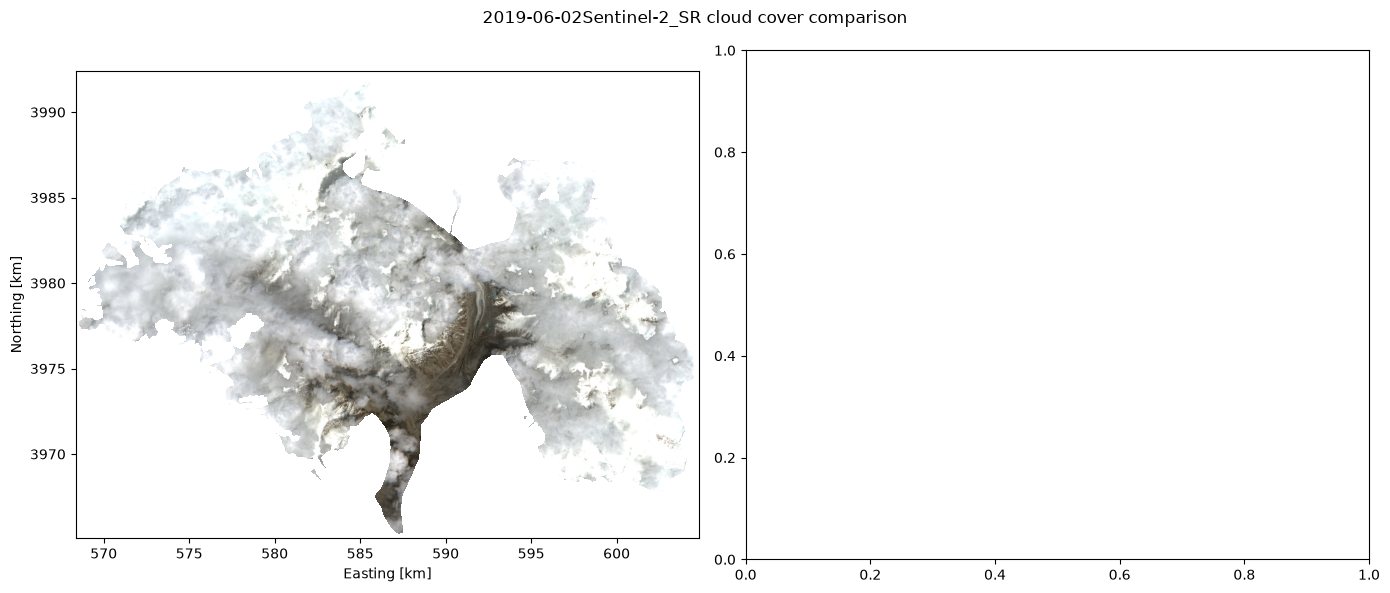

In [197]:
# Define dataset
dataset = 'Sentinel-2_SR'
SR_cloud_filt_imgs = []
cloud_mask = True
for img in SR_non_filt_imgs:
    date = img.attrs['date']
    new_date_start = (pd.to_datetime(date) - pd.Timedelta(days=1)).strftime('%Y-%m-%d')
    new_date_end = (pd.to_datetime(date) + pd.Timedelta(days=1)).strftime('%Y-%m-%d')
    result = query_gee_for_imagery(aoi_utm, dataset, new_date_start, new_date_end, month_start, month_end, cloud_mask, max_cloud_cover, min_aoi_coverage,
                                im_download, s2_sr_im_path, dataset_dict, site_name, im_classified_path,
                                snow_cover_stats_path, clf, feature_cols, figures_out_path, plot_results, verbose, delineate_snowline)
    plot_cloud_cover_comp(img, result, dataset_dict, date, dataset, figures_out_path)
    SR_cloud_filt_imgs.append(result)

## Landsat 8/9

In [178]:
# -----Query GEE for imagery (and download to l_im_path if necessary)
# Define dataset
dataset = 'Landsat'
# Load trained image classifier
clf_fn = os.path.join(script_path, '..', 'inputs-outputs', 'Landsat_classifier_all_sites.joblib')
clf = load(clf_fn)
# Load feature columns (bands to use in classification)
feature_cols_fn = os.path.join(script_path, '..', 'inputs-outputs', 'Landsat_feature_columns.json')
feature_cols = json.load(open(feature_cols_fn))
# Run the classification pipeline
im_download=True
cloud_mask = False
LS_non_filt_imgs = query_gee_for_imagery(aoi_utm, dataset, date_start, date_end, month_start, month_end, cloud_mask, max_cloud_cover, min_aoi_coverage,
                                im_download, l_im_path_no_filter, dataset_dict, site_name, im_classified_path,
                                snow_cover_stats_path, clf, feature_cols, figures_out_path, plot_results, verbose, delineate_snowline)

Splitting date range by month for image query.
Number of date ranges = 1
Number of date ranges to loop through = 1


  0%|          | 0/1 [00:00<?, ?it/s]

date range for image query = ('2019-06-01', '2019-06-30')
number of dates in subsetted image collection 4


  0%|          | 0/4 [00:00<?, ?it/s]

20190604_Landsat.tif: |        | 0.00/86.0M (raw) [  0.0%] in 00:00 (eta:     ?)

20190613_Landsat.tif: |        | 0.00/86.0M (raw) [  0.0%] in 00:00 (eta:     ?)

20190620_Landsat.tif: |        | 0.00/86.0M (raw) [  0.0%] in 00:00 (eta:     ?)

20190629_Landsat.tif: |        | 0.00/86.0M (raw) [  0.0%] in 00:00 (eta:     ?)

Splitting date range by month for image query.
Number of date ranges = 1
Number of date ranges to loop through = 1


  0%|          | 0/1 [00:00<?, ?it/s]

date range for image query = ('2019-06-03', '2019-06-05')
Image sizes exceed GEE user limit, images must be downloaded to file.
number of dates in subsetted image collection 0


0it [00:00, ?it/s]

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.394715..1.23319].


...

date range for image query = ('2019-06-28', '2019-06-30')
Image sizes exceed GEE user limit, images must be downloaded to file.
number of dates in subsetted image collection 1


  0%|          | 0/1 [00:00<?, ?it/s]

20190629_Landsat.tif: |        | 0.00/86.0M (raw) [  0.0%] in 00:00 (eta:     ?)

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.1954075..1.3380475].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.1954075..1.3380475].


Figure saved to file:/Users/SILASTWICKLER/ws/HMA/snowCover/study_sites/Panmah_Glacier/AOIs//test_cloud_filter/20/figures/20190629Landsat_cloud_cover_comparison.png


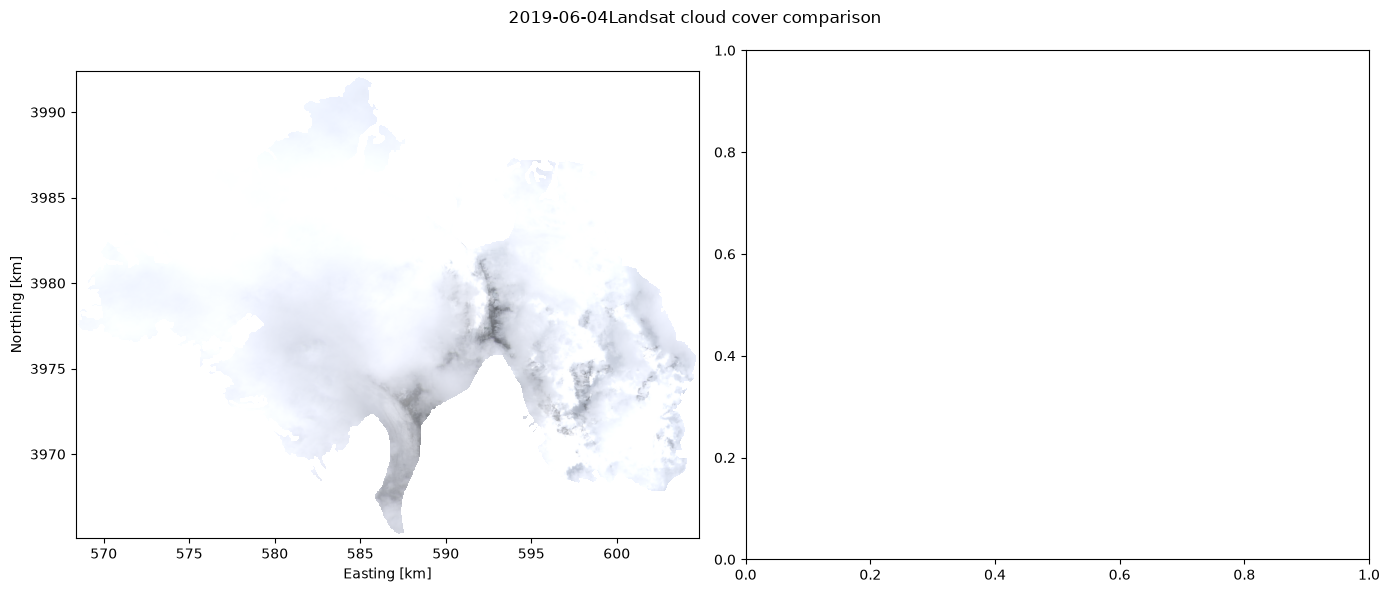

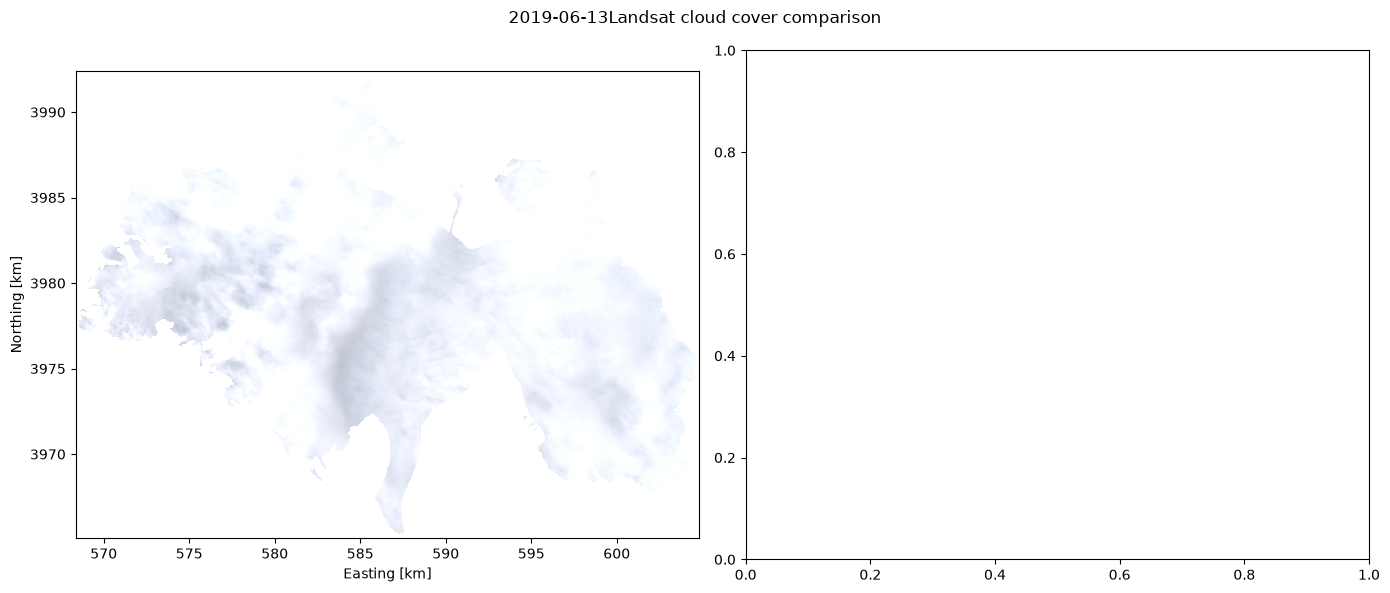

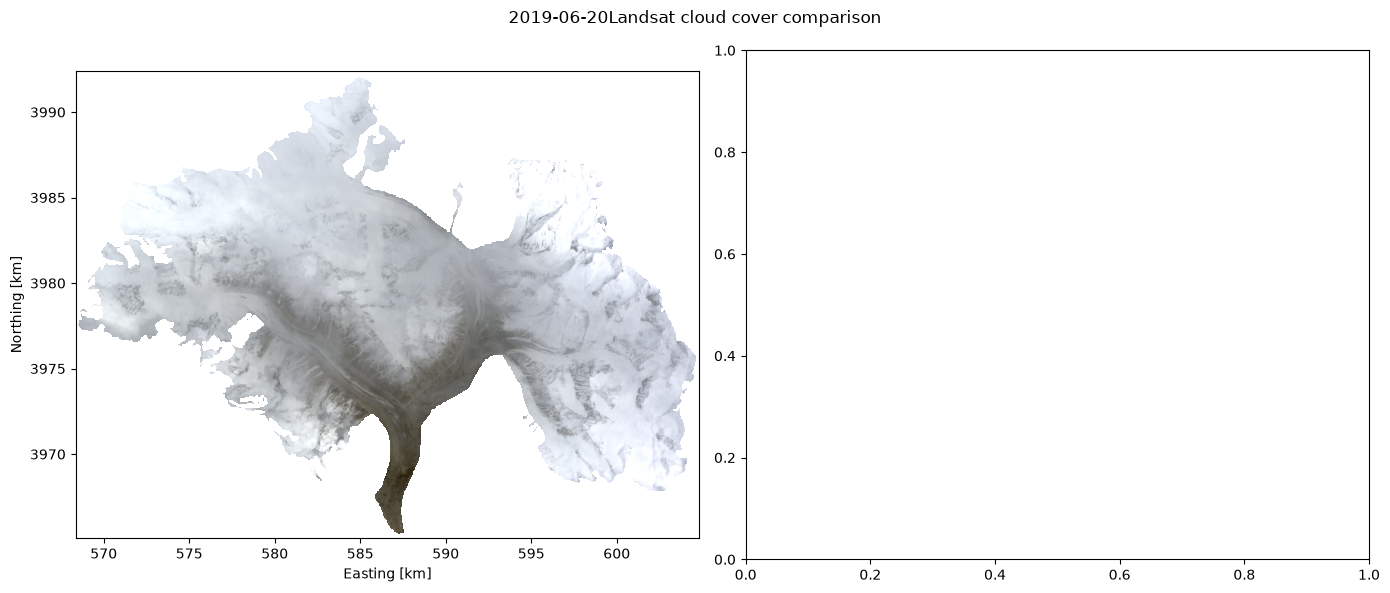

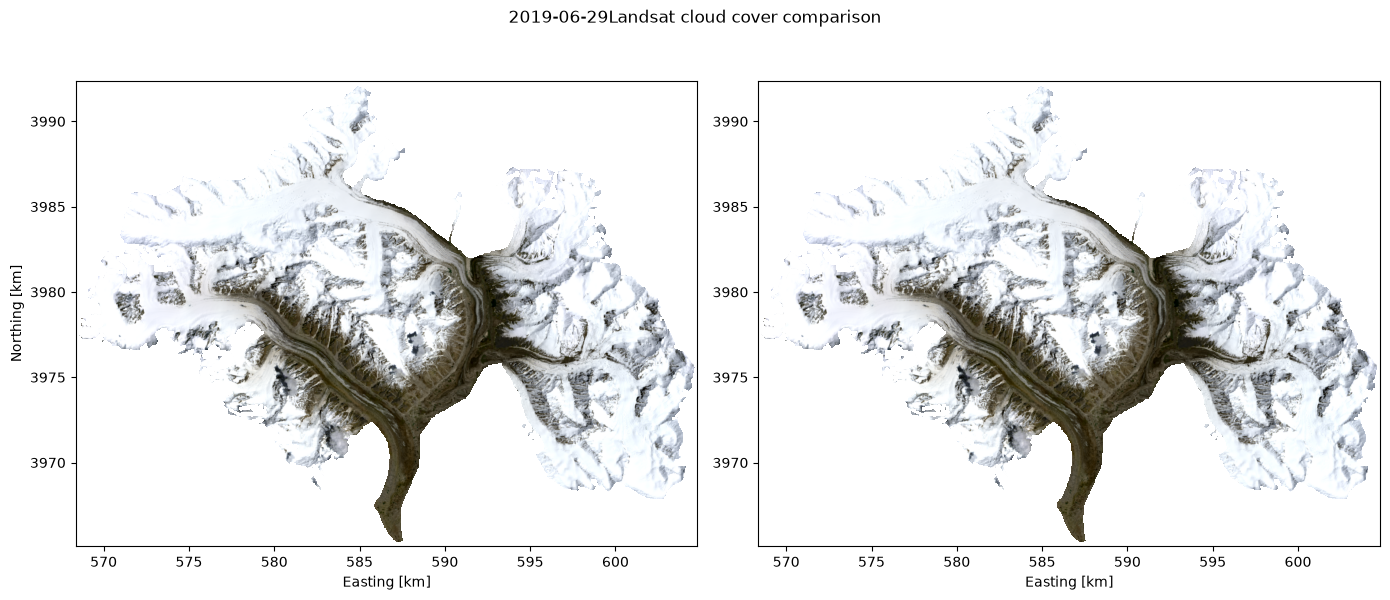

In [194]:
# Define dataset
dataset = 'Landsat'
LS_cloud_filt_imgs = []
cloud_mask = True
for img in LS_non_filt_imgs:
    date = img.attrs['date']
    new_date_start = (pd.to_datetime(date) - pd.Timedelta(days=1)).strftime('%Y-%m-%d')
    new_date_end = (pd.to_datetime(date) + pd.Timedelta(days=1)).strftime('%Y-%m-%d')
    result = query_gee_for_imagery(aoi_utm, dataset, new_date_start, new_date_end, month_start, month_end, cloud_mask, max_cloud_cover, min_aoi_coverage,
                                im_download, l_im_path, dataset_dict, site_name, im_classified_path,
                                snow_cover_stats_path, clf, feature_cols, figures_out_path, plot_results, verbose, delineate_snowline)
    plot_cloud_cover_comp(img, result, dataset_dict, date, dataset, figures_out_path)
    LS_cloud_filt_imgs.append(result)

## Cloud Filter

In [ ]:
#Function to calculate the average cloud percentage within a ROI
#---------------------------------------------------------------------------
def S2cloudpercent(image,ROI):
    aveCloud = image.select('MSK_CLDPRB').reduceRegion(
        reducer=ee.Reducer.mean(),
        geometry=ROI,
        maxPixels=1e9
        )
    return image.set({'CLOUDY_PIXEL_PERCENTAGE': aveCloud.get('MSK_CLDPRB')})

# Filter S2 collection 
#---------------------------------------------------------------------------

S2_filtered = S2_collection \
    .filterDate(DateStart, DateEnd) \
    .filterBounds(bbox) \
    .map(lambda image: S2cloudpercent(image, bbox)) \
    .filterMetadata('CLOUDY_PIXEL_PERCENTAGE', "less_than",15)\
    .limit(50)